# What does a neural network see? Classifying images with AlexNet
**Reading:** Lindsay, G. W. (2021). Convolutional neural networks as a model of the visual system: Past, present, and future. *Journal of Cognitive Neuroscience, 33*(10), 2017–2031.

**Background:** Krizhevsky, A., Sutskever, I., & Hinton, G. E. (2012). ImageNet classification with deep convolutional neural networks. *NeurIPS, 25*.

Last week you loaded AlexNet and classified a single image. AlexNet was trained on **ImageNet**: about 1.2 million photos, each labelled with one of **1,000 categories**. Today we test how far its recognition goes. Each object comes in five versions, each one further away from what AlexNet was trained on:

| Version | What it is |
|---|---|
| `imagenet` | a photo from ImageNet |
| `photo` | a new photo of the same kind of object, not from ImageNet |
| `drawing` | a coloured drawing of the object |
| `outline` | a black-and-white line drawing of the object |
| `toy` | a toy version of the object |

We also test two **unknown** things: objects that have no label among the 1,000 categories.

**What you will do**
1. Look at the 1,000 labels AlexNet knows
2. Classify the five versions of each object and look at the top-5 predictions
3. See what AlexNet does with things it has no label for
4. Compare how confident AlexNet is on each version

## Setup

In [16]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import torch
from torchvision import models, transforms
device = "cpu"

In [17]:
# Find the course data in Sciebo (works even if the shared folder was renamed)
matches = list(Path.home().glob("sciebo/*/Week3/"))
if not matches:
    raise FileNotFoundError(
        "Course data not found. Did you connect Sciebo when starting the server, "
        "and accept the shared CNU folder in Sciebo?"
    )
DATA = matches[0]
IMAGE_DIR = DATA / "images"
print(f"Using data from {DATA}")

Using data from /home/e/eilkel/sciebo/CNU/Week3


## 1. Load AlexNet (as in Week 2)

In [18]:
# Load AlexNet with its trained weights (like ResMem(pretrained=True)).
# The first time, the weights (about 230 MB) are downloaded from the internet;
# after that they are stored on your server and load quickly.
weights = models.AlexNet_Weights.IMAGENET1K_V1   # the official ImageNet-trained version
model = models.alexnet(weights=weights)

# .eval() switches off training-only behaviour (dropout), so predictions are stable
model = model.to(device).eval()

# The names of the 1,000 categories, in the order of the network's outputs
categories = weights.meta["categories"]
print(f"AlexNet knows {len(categories)} categories")

AlexNet knows 1000 categories


### Which categories does AlexNet know?
AlexNet can only answer with one of these 1,000 labels. Let's look at some of them.

In [19]:
# 20 random labels
rng = np.random.default_rng(0)        # change the number to see other labels
for i in rng.choice(len(categories), 20, replace=False):
    print(i, categories[i])

905 window shade
303 long-horned beetle
265 toy poodle
935 mashed potato
502 clog
602 horizontal bar
559 folding chair
965 burrito
625 lifeboat
643 mask
173 Ibizan hound
805 soccer ball
630 Loafer
16 bulbul
542 drumstick
74 garden spider
834 suit
500 cliff dwelling
726 plane
40 American chameleon


In [20]:
def find_labels(word):
    """Print all labels that contain `word`."""
    hits = [(i, c) for i, c in enumerate(categories) if word.lower() in c.lower()]
    for i, c in hits:
        print(i, c)
    print(f"--> {len(hits)} labels contain '{word}'")

find_labels("retriever")

205 flat-coated retriever
206 curly-coated retriever
207 golden retriever
208 Labrador retriever
209 Chesapeake Bay retriever
--> 5 labels contain 'retriever'


**Try it:** search for `"zebra"`, `"plane"`, `"dog"`, `"person"`, `"toy"`. What does the label `plane` actually mean?

- Labels 151–268 are all **dog breeds**: 118 of the 1,000 categories! Why might that be a problem if you want to compare AlexNet with how people name objects?
- Is there a label for "person"? What does that mean for photos of people?
- Are there labels that could fit a **toy** or a **drawing**? Keep them in mind for section 4.

## 2. Load the images
The images are prepared exactly as in Week 2: resized, cropped to the central 224 × 224 pixels, and normalised.

Each filename says what the image shows: `zebra_drawing.png` is the **drawing** version of the object **zebra**. Files starting with `unknown_` are the objects AlexNet has no label for.

In [21]:
# The full preparation that goes into the network
preprocess = transforms.Compose([
    transforms.Resize(256),        # shorter side -> 256 pixels
    transforms.CenterCrop(224),    # cut out the central 224 x 224 square
    transforms.ToTensor(),         # turn the image into numbers (PyTorch's tensor format)
    transforms.Normalize(mean=[0.485, 0.456, 0.406],   # same colour normalisation
                         std=[0.229, 0.224, 0.225]),   # as in ImageNet training
])

# The same steps without the number conversion, so we can SHOW what the network sees
what_network_sees = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])

In [22]:
VERSIONS = ["imagenet", "photo", "drawing", "outline", "toy"]   # from closest to furthest from ImageNet

images = {}     # images[object][version] = image, e.g. images["zebra"]["drawing"]
unknown = {}    # unknown[name] = image, e.g. unknown["giraffe"]

for path in sorted(IMAGE_DIR.iterdir()):
    if path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".webp"}:
        continue                                    # skip anything that is not an image
    img = Image.open(path).convert("RGB")           # RGB = 3 colour channels
    first, _, rest = path.stem.partition("_")       # "zebra_drawing" -> "zebra", "drawing"
    if first == "unknown":
        unknown[rest] = img
    elif rest in VERSIONS:
        images.setdefault(first, {})[rest] = img
    else:
        print(f"Skipped {path.name}: name should be <object>_<version>, e.g. zebra_drawing.png")

objects = list(images)
print(f"Objects: {objects}")
print(f"Unknown things: {list(unknown)}")

Objects: ['plane', 'zebra']
Unknown things: ['giraffe', 'helicopter']


## 3. Helper functions: classify and show the top-5

In [23]:
def classify(imgs, k=5):
    """Return the k most likely labels and their probabilities for each image."""
    # Prepare all images and stack them into one batch
    batch = torch.stack([preprocess(img) for img in imgs]).to(device)

    # We only predict, we don't train: no gradients needed
    with torch.no_grad():
        outputs = model(batch)                    # shape: (number of images, 1000)

    # Softmax turns the 1,000 raw outputs into probabilities that sum to 1
    probs = torch.softmax(outputs, dim=1)

    # Keep the k highest probabilities and their category numbers
    top_probs, top_idx = probs.topk(k, dim=1)

    results = []
    for p_row, i_row in zip(top_probs, top_idx):
        results.append([(categories[i], p.item()) for p, i in zip(p_row, i_row)])
    return results


def show_top5(images, names, results, title=None):
    """One row per image: the image on the left, its top-5 predictions on the right."""
    n = len(images)
    fig, axes = plt.subplots(n, 2, figsize=(9, 2.3 * n), gridspec_kw={"width_ratios": [1, 1.7]})
    axes = np.atleast_2d(axes)
    for row, (img, name, res) in enumerate(zip(images, names, results)):
        ax_img, ax_bar = axes[row]
        ax_img.imshow(what_network_sees(img)); ax_img.axis("off")
        ax_img.set_title(name, fontsize=10)

        labels = [label for label, _ in res][::-1]   # reversed, so the top guess is on top
        probs  = [p for _, p in res][::-1]
        ax_bar.barh(labels, probs, color="tab:blue")
        ax_bar.set_xlim(0, 1)
        for y, p in enumerate(probs):
            ax_bar.text(p + 0.01, y, f"{p:.2f}", va="center", fontsize=9)
    axes[-1, 1].set_xlabel("probability")
    if title:
        fig.suptitle(title)
    plt.tight_layout(); plt.show()

## 4. The five versions of each object
### Your turn first
**Before running the classification**, look at the images below. For each one, write down: will AlexNet get it right? How sure will it be?

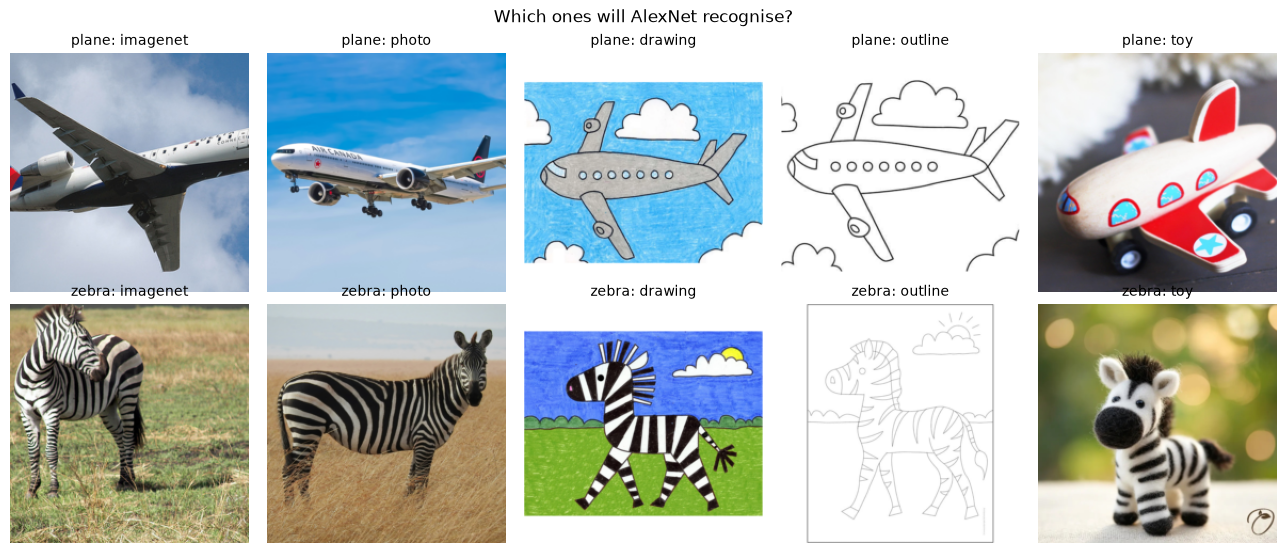

In [24]:
# One row per object, one column per version
fig, axes = plt.subplots(len(objects), len(VERSIONS),
                         figsize=(2.6 * len(VERSIONS), 2.8 * len(objects)), squeeze=False)
for row, obj in enumerate(objects):
    for col, version in enumerate(VERSIONS):
        ax = axes[row, col]
        ax.axis("off")
        if version in images[obj]:
            ax.imshow(what_network_sees(images[obj][version]))
            ax.set_title(f"{obj}: {version}", fontsize=10)
fig.suptitle("Which ones will AlexNet recognise?")
plt.tight_layout(); plt.show()

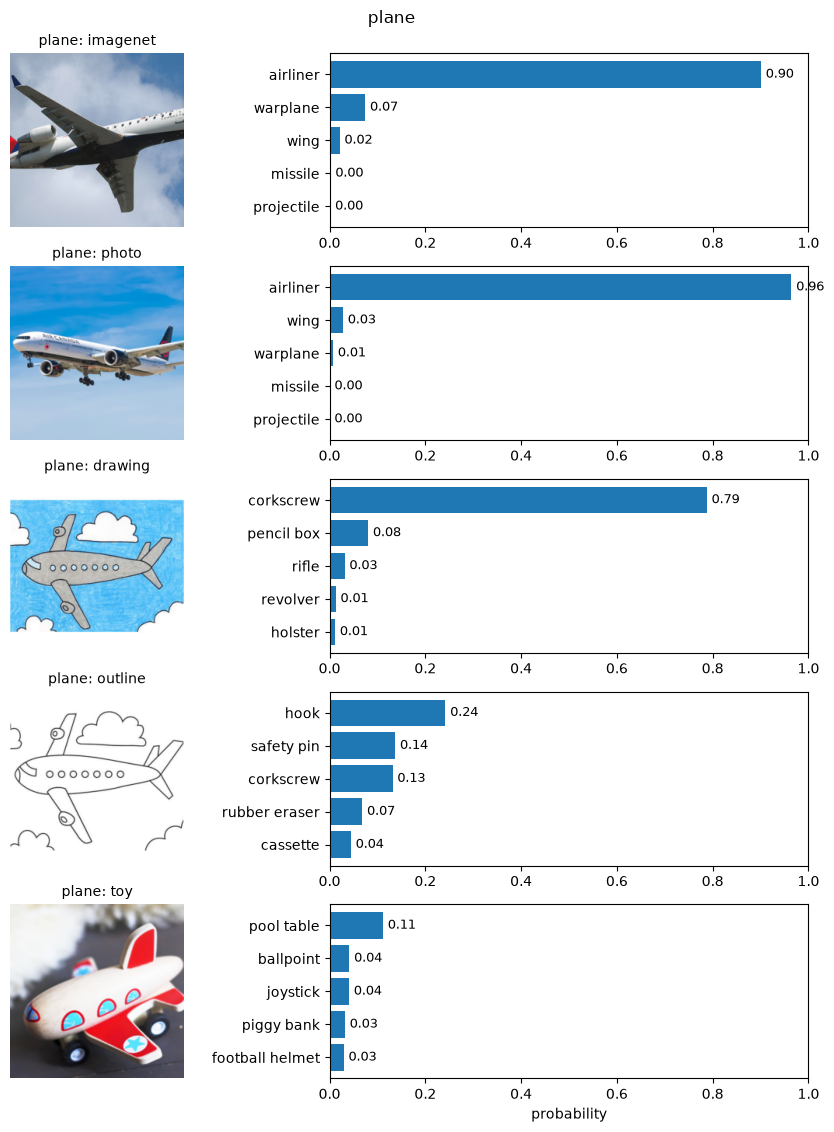

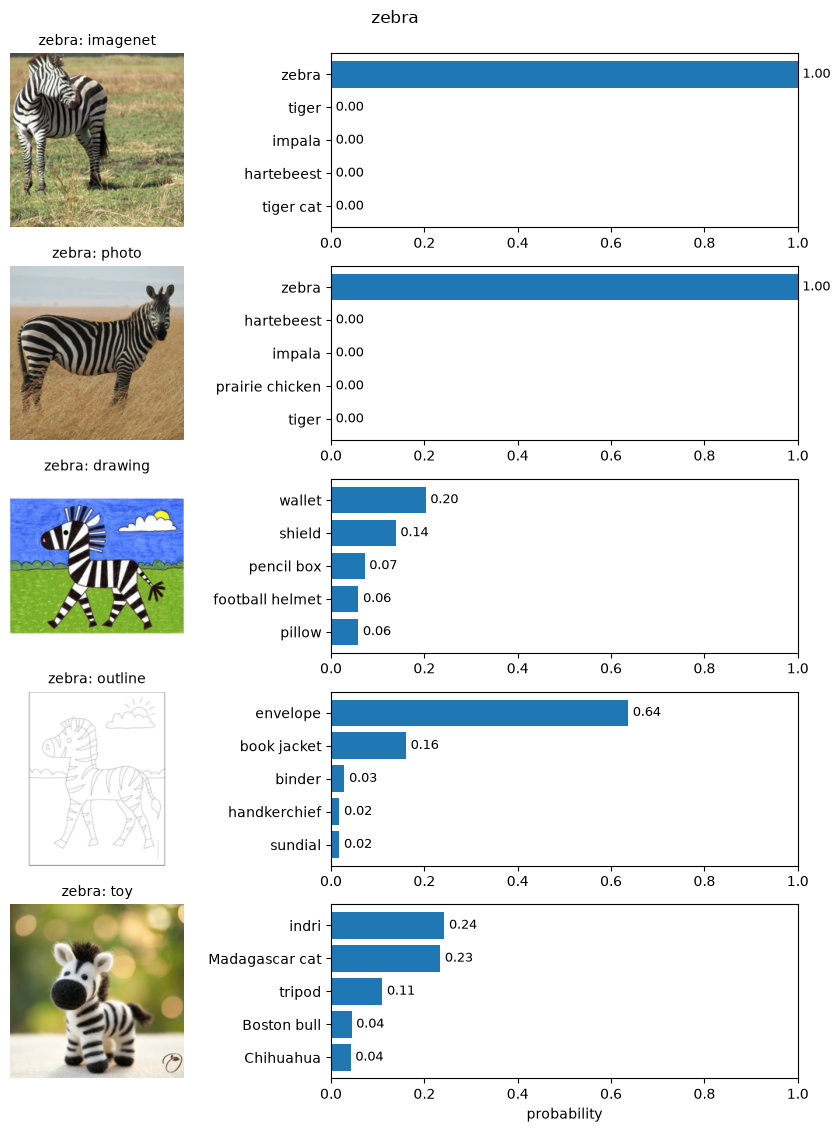

In [25]:
# Classify every version of every object and show the top-5
results = {}    # results[object][version] = top-5 list
for obj in objects:
    versions = [v for v in VERSIONS if v in images[obj]]
    imgs = [images[obj][v] for v in versions]
    res = classify(imgs)
    results[obj] = dict(zip(versions, res))
    show_top5(imgs, [f"{obj}: {v}" for v in versions], res, title=obj)

**Think about it:**
- At which version does AlexNet stop recognising the object? Is it the same for both objects?
- When it is wrong, is it *completely* wrong? Look at the 2nd–5th guesses: do they **look** similar to the object (shape, colour, texture), or do they **mean** something similar?
- Did the toy get a label like "teddy bear" or "toyshop"? Is that wrong, or is AlexNet describing what it sees?
- Would a 5-year-old recognise all five versions? (Keep this question for Week 7!)

## 5. Things AlexNet has no label for
None of these objects has a label among the 1,000 categories. But AlexNet **has to** answer: its probabilities always add up to 1. There is no "I don't know" option.

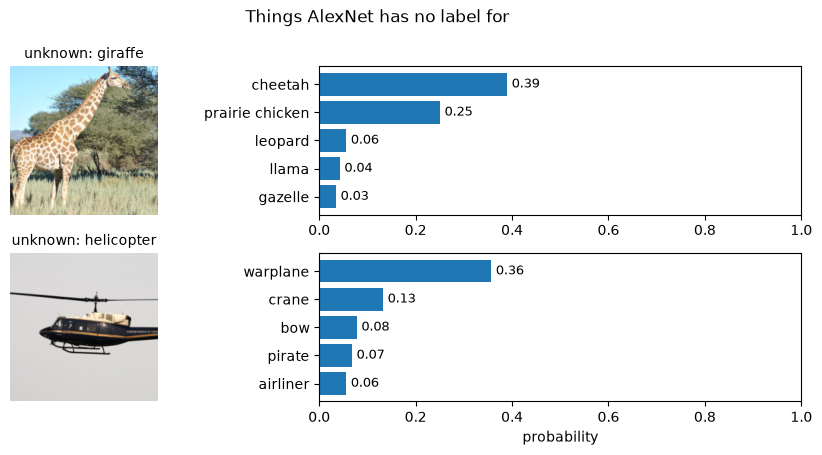

In [26]:
unknown_names = list(unknown)
unknown_imgs = [unknown[name] for name in unknown_names]
unknown_results = classify(unknown_imgs)
show_top5(unknown_imgs, [f"unknown: {n}" for n in unknown_names], unknown_results,
          title="Things AlexNet has no label for")

**Think about it:**
- Do the guesses make sense to you? Why might AlexNet have chosen them?
- Is AlexNet unsure (low, spread-out probabilities), or confidently wrong?

**Think about it:**
- Does confidence drop from `imagenet` to `toy`? For both objects? Is the outline harder than the coloured drawing?
- Is AlexNet ever **very** confident and wrong?
- Can we use the confidence to tell whether the network "knows" what it is looking at?

## 7. Explore: your own object
Pick an object you think AlexNet knows (check with `find_labels()`) and find a **photo**, a **drawing** and a **toy** version of it online.

1. In the file browser on the left, create a folder called `my_images`.
2. Upload your images into it and name them like the course images: `<object>_<version>`, e.g. `cup_photo.jpg`, `cup_drawing.png`, `cup_toy.jpg`. You can also add an `outline` version.
3. Run the cells below.

Your images can have any shape: they are first put on a **white square**, so the centre crop does not cut anything off.

In [ ]:
def pad_to_square(img, fill="white"):
    """Put the image on a white square, with enough margin that the centre crop
    only removes white space. This way nothing of the object is cut off."""
    w, h = img.size
    size = round(max(w, h) * 256 / 224) + 4         # the crop keeps 224 of 256 pixels
    square = Image.new("RGB", (size, size), fill)
    square.paste(img, ((size - w) // 2, (size - h) // 2))   # paste the image in the centre
    return square

MY_DIR = Path("my_images")
my_images = {}  # my_images[object][version] = image

for path in sorted(MY_DIR.iterdir()):
    if path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".webp"}:
        continue
    obj, _, version = path.stem.partition("_")
    if version not in VERSIONS:
        print(f"Skipped {path.name}: name should be <object>_<version>, e.g. cup_drawing.png")
        continue
    img = pad_to_square(Image.open(path).convert("RGB"))
    my_images.setdefault(obj, {})[version] = img

print(f"Your objects: {list(my_images)}")

In [ ]:
for obj in my_images:
    versions = [v for v in VERSIONS if v in my_images[obj]]
    imgs = [my_images[obj][v] for v in versions]
    show_top5(imgs, [f"{obj}: {v}" for v in versions], classify(imgs), title=f"Your object: {obj}")

**Think about it:** does your object break down at the same version as the zebra and the plane? Can you find a drawing or toy that AlexNet still recognises with high confidence?

## 8. Discussion questions
1. AlexNet is very good at ImageNet photos. Does that make it a good model of how **humans** recognise objects? What else would you want to test?
2. Humans recognise a drawing of a zebra without effort, even though drawings look very different from real zebras. What might humans use that AlexNet does not?